# Milestone M2.1 — RQ1: Generalization to Unseen Landing Pages
## Project: Recut Research Lab 01 — Advertising Consistency & Claim Verification

---

## 1. Research Question and Hypotheses

**Research Question (RQ1)**:
> *How well do advertising consistency classifiers generalize to landing pages that were never observed during model training?*

Motivated by M1 (920 repeated landing pages in `train.tsv`), M2.0 (`B3_pair` validation failure at default threshold), and M2.0.1 (where standard random 5-fold StratifiedKFold on `train` yielded `+0.21 to +0.34` higher Average Precision than official `valid`), Milestone M2.1 performs a controlled comparison between **Protocol A (Conventional StratifiedKFold)** and **Protocol B (Landing-Page-Group-Disjoint StratifiedGroupKFold)** exclusively within the official training split.

### Research Hypotheses
- **H1**: Conventional `StratifiedKFold` may report higher performance than LP-group-disjoint cross-validation because training and evaluation folds can share landing pages.
- **H2**: `B2_lp_only` may be especially sensitive to evaluation-group overlap because it relies exclusively on landing-page predictive signals.
- **H3**: Differences between the two validation protocols may also reflect changes in fold class prevalence, unequal group sizes, and fold composition rather than memorization alone.

> [!IMPORTANT]
> **Scope & Data Protection**: Official `valid.tsv` and `test.tsv` are **strictly excluded** and never read from disk during M2.1. The goal is to quantify generalization behavior, not to maximize performance or tune hyperparameters.

## 2. Dataset and Provenance

**QUESTION**: Is `train.tsv` cryptographically verified against M1 provenance, and are `valid.tsv` and `test.tsv` confirmed untouched throughout M2.1?

**METHOD**: Load ONLY `data/raw/adtec_consistency/train.tsv` via `recut_lab.generalization.load_adtec_train_only` and load persisted RQ1 experiment artifacts from `experiments/runs/m2_generalization_v001/` (automatically executing `run_rq1_generalization_study` if artifacts do not exist).

In [1]:
# Environment setup, visual design system, and train-only provenance verification
import json
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path('..').resolve()
SRC_PATH = REPO_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from recut_lab.generalization import (
    PROTOCOL_A,
    PROTOCOL_B,
    load_adtec_train_only,
    run_rq1_generalization_study,
)

# Japanese-inspired research palette
IVORY = '#F7F3EA'
INDIGO = '#33415C'
VERMILION = '#C65D4B'
MATCHA = '#71816D'
GRAY = '#8A8A86'
MODEL_COLORS = {
    'B0_majority': GRAY,
    'B1_title_only': INDIGO,
    'B2_lp_only': MATCHA,
    'B3_pair': VERMILION,
}
PROTO_LABELS = {
    PROTOCOL_A: 'Protocol A (Stratified CV)',
    PROTOCOL_B: 'Protocol B (LP-Group-Disjoint CV)',
}

mpl.rcParams['font.sans-serif'] = [
    'Meiryo', 'Yu Gothic', 'MS Gothic', 'Noto Sans CJK JP',
    'TakaoPGothic', 'DejaVu Sans', 'sans-serif',
]
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['figure.facecolor'] = IVORY
mpl.rcParams['axes.facecolor'] = IVORY
mpl.rcParams['axes.edgecolor'] = GRAY
mpl.rcParams['grid.color'] = GRAY

DATA_DIR = REPO_ROOT / 'data' / 'raw' / 'adtec_consistency'
RUN_DIR = REPO_ROOT / 'experiments' / 'runs' / 'm2_generalization_v001'
FIG_DIR = REPO_ROOT / 'reports' / 'generated' / 'm2_generalization'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Strictly load train.tsv ONLY (valid.tsv and test.tsv are never opened)
train_df, provenance = load_adtec_train_only(DATA_DIR)

if not (RUN_DIR / 'generalization_metrics.json').is_file():
    cfg = json.loads((REPO_ROOT / 'configs' / 'm2_generalization.json').read_text(encoding='utf-8'))
    run_rq1_generalization_study(
        config=cfg, data_dir=DATA_DIR,
        runs_base_dir=REPO_ROOT / 'experiments' / 'runs',
        reports_dir=FIG_DIR,
    )

rq1_payload = json.loads((RUN_DIR / 'generalization_metrics.json').read_text(encoding='utf-8'))
group_dist_df = pd.read_csv(RUN_DIR / 'group_distribution.csv')
fold_integrity_df = pd.read_csv(RUN_DIR / 'fold_integrity.csv')
per_fold_df = pd.read_csv(RUN_DIR / 'per_fold_metrics.csv')
protocol_comp_df = pd.read_csv(RUN_DIR / 'protocol_comparison.csv')
oof_df = pd.read_csv(RUN_DIR / 'oof_predictions.csv')

display(pd.DataFrame([{'Field': k, 'Value': v} for k, v in provenance.items()]))

,Field,Value
0,dataset_name,cyberagent/AdTEC
1,config_name,ad-consistency
2,license,CC BY-NC-SA 4.0
3,upstream_revision,f8d1c64a369eba2093d783e2b6f530bb3951f6f2
4,train_filename,train.tsv
5,train_row_count,10635
6,train_sha256_verified,5ce99c78564856963911d667fc183416878fad6ea5e753...
7,train_sha256_matches_metadata,True
8,valid_split_loaded,False
9,test_split_loaded,False


**OBSERVATION**: `train.tsv` (`N = 10,635` rows, SHA-256 `5ce99c7856485696...`, upstream revision `f8d1c64a369eba2093d783e2b6f530bb3951f6f2`) verified intact against M1 metadata; `valid_split_loaded = False` and `test_split_loaded = False`.

**INTERPRETATION**: All subsequent RQ1 analyses operate strictly inside the official training split.

**LIMITATION**: Official validation and test splits remain intentionally isolated from this experiment.

## 3. Landing-Page Group Definition

Deterministic landing-page group identifiers are constructed solely from `lp_text` without consulting class labels:
1. Apply Unicode NFKC normalization and collapse redundant whitespace (`recut_lab.preprocessing.normalize_japanese_text`).
2. Hash each unique normalized landing-page text via SHA-256 into an anonymous, deterministic identifier `lp_grp_<12-hex>`.
3. Apply the identical normalization across all group audits, fold splits, and integrity checks.

This guarantees zero label leakage in group construction and ensures no raw Japanese landing-page text is persisted in tracked CSV artifacts.

## 4. Landing-Page Group Distribution Audit

**QUESTION**: How concentrated are training examples across unique landing pages, how many groups are single-class vs. mixed-label, and does the group structure permit meaningful group-disjoint cross-validation?

**METHOD**: Summarize group-size quantiles, Gini concentration, Herfindahl-Hirschman Index (`HHI`) effective group count (`1 / HHI`), single-class vs. mixed-label counts (**Group Distribution Summary Table**), and render **Figure 1** (group-size distribution), **Figure 2** (cumulative record coverage), and **Figure 3** (class breakdown across top 15 LP groups).

,group_count,sample_count,mean_group_size,median_group_size,p75_group_size,p90_group_size,p95_group_size,p99_group_size,max_group_size,single_class_group_count,mixed_label_group_count,top10_sample_pct,effective_group_count,gini_concentration
0,920,10635,11.56,3.0,6.0,27.1,58.0,147.34,588,652,268,22.13,102.77,0.7568


Top 10 Largest Anonymous LP Groups in train.tsv:


,group_id,sample_count,consistent_count,inconsistent_count,inconsistent_pct,sample_share_pct,cumulative_share_pct
0,lp_grp_a999c9d349e1,588,45,543,92.35,5.5289,5.5289
1,lp_grp_ff59187beebf,272,141,131,48.16,2.5576,8.0865
2,lp_grp_7e168e25f68e,263,196,67,25.48,2.4730,10.5595
3,lp_grp_b0b6a76512c1,210,184,26,12.38,1.9746,12.5341
4,lp_grp_f3f37899db95,185,70,115,62.16,1.7395,14.2736
5,lp_grp_e6cce6a275eb,181,95,86,47.51,1.7019,15.9755
6,lp_grp_b71fb5183b39,172,164,8,4.65,1.6173,17.5928
7,lp_grp_075bad0939d8,167,32,135,80.84,1.5703,19.1631
8,lp_grp_656de62fdf84,166,106,60,36.14,1.5609,20.7240
9,lp_grp_0d5652d226b3,150,74,76,50.67,1.4104,22.1344


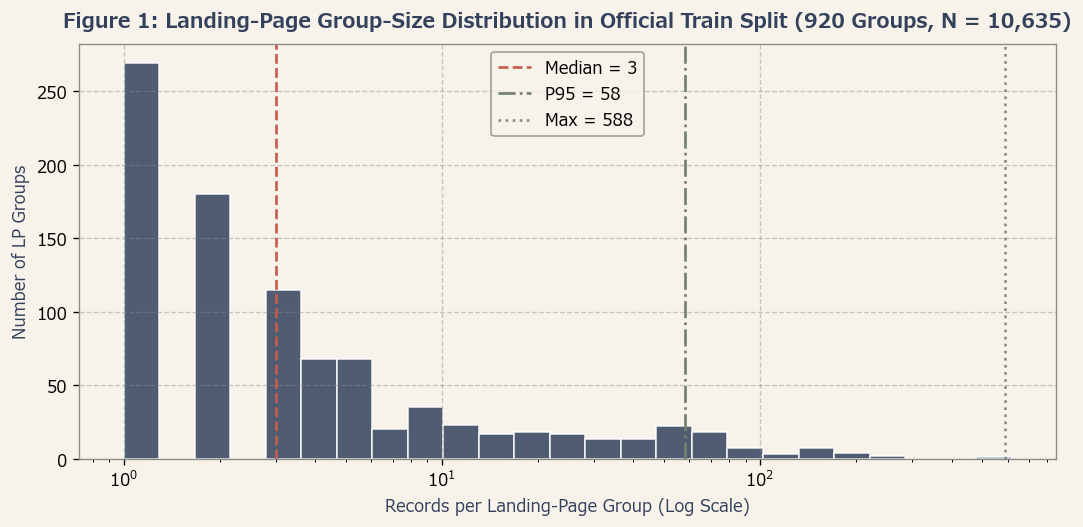

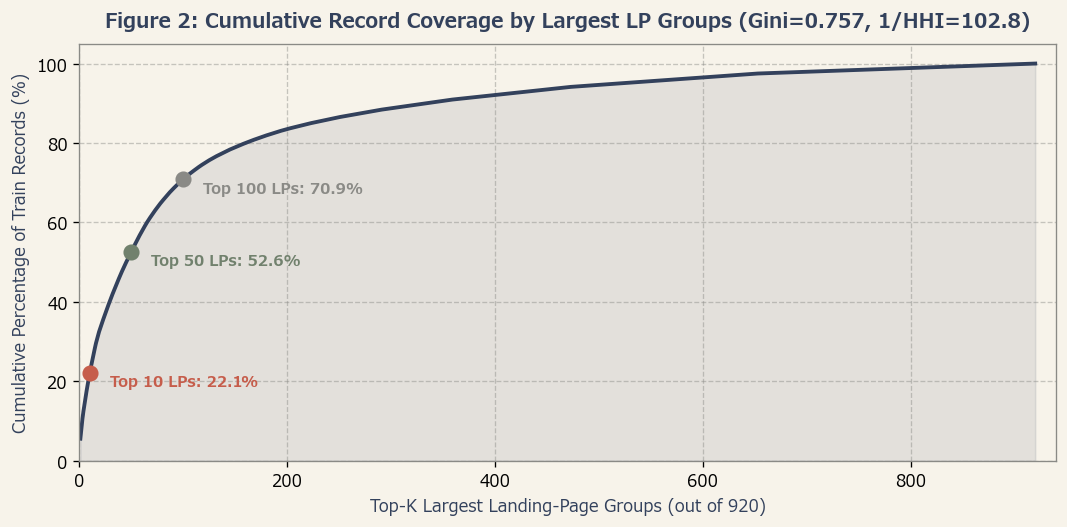

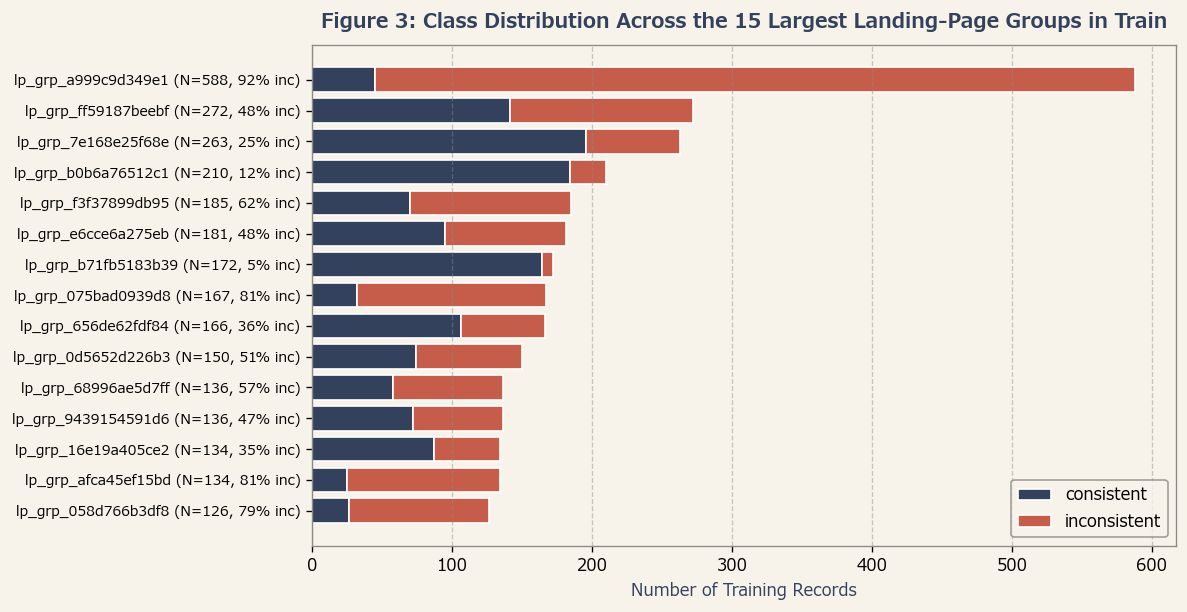

Caption: Top LP groups show strong heterogeneity in size (up to 588 records) and inconsistent class prevalence.


In [2]:
# GROUP DISTRIBUTION SUMMARY TABLE
gs = rq1_payload['group_distribution_summary']
group_summary_table = pd.DataFrame([{
    'group_count': gs['group_count'],
    'sample_count': gs['sample_count'],
    'mean_group_size': gs['mean_group_size'],
    'median_group_size': gs['median_group_size'],
    'p75_group_size': gs['p75_group_size'],
    'p90_group_size': gs['p90_group_size'],
    'p95_group_size': gs['p95_group_size'],
    'p99_group_size': gs['p99_group_size'],
    'max_group_size': gs['max_group_size'],
    'single_class_group_count': gs['single_class_group_count'],
    'mixed_label_group_count': gs['mixed_label_group_count'],
    'top10_sample_pct': gs['top10_group_sample_pct'],
    'effective_group_count': gs['effective_group_count'],
    'gini_concentration': gs['gini_concentration'],
}])
display(group_summary_table)

print('Top 10 Largest Anonymous LP Groups in train.tsv:')
display(group_dist_df.head(10)[['group_id', 'sample_count', 'consistent_count', 'inconsistent_count', 'inconsistent_pct', 'sample_share_pct', 'cumulative_share_pct']])

# FIGURE 1 — Landing-Page Group-Size Distribution
fig, ax = plt.subplots(figsize=(9.0, 4.5), dpi=120)
sizes = group_dist_df['sample_count'].to_numpy()
log_bins = np.logspace(0, np.log10(sizes.max() * 1.05), 26)
ax.hist(sizes, bins=log_bins, color=INDIGO, alpha=0.85, edgecolor='white')
ax.set_xscale('log')
ax.axvline(gs['median_group_size'], color=VERMILION, linestyle='--', linewidth=1.6, label=f"Median = {gs['median_group_size']:.0f}")
ax.axvline(gs['p95_group_size'], color=MATCHA, linestyle='-.', linewidth=1.6, label=f"P95 = {gs['p95_group_size']:.0f}")
ax.axvline(gs['max_group_size'], color=GRAY, linestyle=':', linewidth=1.6, label=f"Max = {gs['max_group_size']}")
ax.set_title('Figure 1: Landing-Page Group-Size Distribution in Official Train Split (920 Groups, N = 10,635)',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.set_xlabel('Records per Landing-Page Group (Log Scale)', fontsize=10, color=INDIGO)
ax.set_ylabel('Number of LP Groups', fontsize=10, color=INDIGO)
ax.grid(True, which='major', linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig1_lp_group_size_distribution.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()

# FIGURE 2 — Cumulative Record Coverage by Largest LP Groups
fig, ax = plt.subplots(figsize=(9.0, 4.5), dpi=120)
ranks = np.arange(1, len(group_dist_df) + 1)
ax.plot(ranks, group_dist_df['cumulative_share_pct'], color=INDIGO, linewidth=2.3, label='Cumulative % of Train Records')
ax.fill_between(ranks, group_dist_df['cumulative_share_pct'], color=INDIGO, alpha=0.10)
for k_mark, col_m in [(10, VERMILION), (50, MATCHA), (100, GRAY)]:
    cov = float(group_dist_df.iloc[k_mark - 1]['cumulative_share_pct'])
    ax.scatter([k_mark], [cov], s=75, color=col_m, zorder=5)
    ax.annotate(f'Top {k_mark} LPs: {cov:.1f}%', xy=(k_mark, cov), xytext=(12, -8),
                textcoords='offset points', fontsize=9, fontweight='bold', color=col_m)
ax.set_title(f"Figure 2: Cumulative Record Coverage by Largest LP Groups (Gini={gs['gini_concentration']:.3f}, 1/HHI={gs['effective_group_count']:.1f})",
             fontsize=11.8, fontweight='bold', color=INDIGO, pad=10)
ax.set_xlabel('Top-K Largest Landing-Page Groups (out of 920)', fontsize=10, color=INDIGO)
ax.set_ylabel('Cumulative Percentage of Train Records (%)', fontsize=10, color=INDIGO)
ax.set_xlim(0, len(group_dist_df) + 20)
ax.set_ylim(0, 105)
ax.grid(True, linestyle='--', alpha=0.45)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig2_cumulative_lp_coverage.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()

# FIGURE 3 — Class Distribution Across Top 15 Largest LP Groups
top15 = group_dist_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10.0, 5.2), dpi=120)
y_pos = np.arange(len(top15))
ax.barh(y_pos, top15['consistent_count'], color=INDIGO, edgecolor='white', label='consistent')
ax.barh(y_pos, top15['inconsistent_count'], left=top15['consistent_count'], color=VERMILION, edgecolor='white', label='inconsistent')
ax.set_yticks(y_pos)
ax.set_yticklabels([f"{gid} (N={n}, {p:.0f}% inc)" for gid, n, p in zip(top15['group_id'], top15['sample_count'], top15['inconsistent_pct'])], fontsize=8.5)
ax.set_xlabel('Number of Training Records', fontsize=10, color=INDIGO)
ax.set_title('Figure 3: Class Distribution Across the 15 Largest Landing-Page Groups in Train',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.grid(axis='x', linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='lower right')
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig3_class_distribution_major_lps.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Top LP groups show strong heterogeneity in size (up to 588 records) and inconsistent class prevalence.')

**OBSERVATION**: Training data (`N = 10,635`) comprises **920 unique normalized LP groups** with extreme right skew: median size = `3.0`, mean = `11.56`, P95 = `58.0`, max = **`588`** (`Gini = 0.7568`, effective group count `1/HHI = 102.77`). The top 10 groups account for **`22.13%`** of all rows (`2,354` rows) and the top 50 account for **`52.62%`**. Crucially, **652 / 920 (`70.87%`)** LP groups are **single-class**, while **268 (`29.13%`)** are mixed-label (`33` groups contain identical pairs with conflicting labels).

**INTERPRETATION**: Because 920 groups exist with `1/HHI = 102.77` effective groups, 5-fold group-disjoint CV is structurally feasible—yet the presence of massive groups (up to `588` rows) and `70.9%` single-class groups guarantees that group-disjoint folds will exhibit uneven fold sizes and class prevalences. Moreover, `70.9%` single-class LPs give any LP-aware classifier a potent shortcut signal whenever LPs are shared across train and evaluation.

**LIMITATION**: Group audit reflects exact normalized `lp_text` identity; near-duplicate LPs (e.g., same website with minor template edits) may still exist across separate group IDs.

## 5. Cross-Validation Protocol Design & Feasibility Check

**QUESTION**: Is `StratifiedGroupKFold` feasible for `n_splits = 3` and `n_splits = 5` on `train.tsv` under predefined structural criteria (no empty folds, both classes well-represented, strict LP disjointness)?

**METHOD**: Inspect feasibility diagnostics for `n_splits = 3` and `n_splits = 5` (`seed = 42`) prior to looking at any model performance. Select one fold count (`n_splits = 5`) and apply it identically to **Protocol A (`StratifiedKFold`)** and **Protocol B (`StratifiedGroupKFold`)** across two predefined seeds (`42` and `123`).

In [3]:
feas = rq1_payload['cv_feasibility']
feas_rows = []
for k_str, info in feas['candidates'].items():
    feas_rows.append({
        'n_splits': info['n_splits'],
        'feasible': info['feasible'],
        'min_eval_size': info['min_eval_size'],
        'max_eval_size': info['max_eval_size'],
        'min_inc_prevalence': info['min_inconsistent_prevalence'],
        'max_inc_prevalence': info['max_inconsistent_prevalence'],
        'prevalence_range': info['prevalence_range'],
    })
display(pd.DataFrame(feas_rows))
print(f"[+] Selected n_splits = {feas['selected_n_splits']}: {feas['selection_rationale']}")

,n_splits,feasible,min_eval_size,max_eval_size,min_inc_prevalence,max_inc_prevalence,prevalence_range
0,3,True,3311,3841,0.3566,0.5107,0.1541
1,5,True,1112,2658,0.2666,0.5754,0.3088


[+] Selected n_splits = 5: n_splits=5 satisfies all predefined feasibility checks (zero empty folds, both classes well-represented in every fold, strict LP disjointness) while retaining ~80% training data per fold and matching the M2.0.1 5-fold convention.


**OBSERVATION**: Both `n_splits = 3` and `n_splits = 5` satisfy all predefined feasibility checks (zero empty folds, strict LP disjointness, both classes well-represented in every fold). `n_splits = 5` retains ~80% training data per fold (`7,910–8,898` rows on `seed = 42`) with `1,737–2,725` evaluation rows and `122–221` unique LPs per fold.

**INTERPRETATION**: `n_splits = 5` across seeds `[42, 123]` (`10` fold evaluations per protocol) provides a balanced, reproducible experimental design without requiring fallback to unstratified `GroupKFold`.

**LIMITATION**: Even with `StratifiedGroupKFold`, keeping the `588`-row largest group intact causes notable fold-size and prevalence fluctuations compared to row-level `StratifiedKFold`.

## 6. Fold Integrity Verification

**QUESTION**: What is the actual measured LP overlap in Protocol A, does Protocol B achieve strict `0%` overlap on every fold, and how do fold sizes and class prevalences compare across protocols?

**METHOD**: Display the complete **Fold Integrity Table** (`20` folds across both protocols and seeds `42`, `123`), assert `shared_lp_count == 0` for every Protocol B fold, and plot **Figure 4** (fold size & class prevalence) and **Figure 5** (LP exposure overlap across protocols).

,protocol,seed,fold,train_size,eval_size,train_unique_lp,eval_unique_lp,shared_lp_count,shared_eval_row_percentage,eval_inconsistent_prevalence
0,protocol_a_stratified,42,0,8508,2127,846,496,422,96.24,0.4114
1,protocol_a_stratified,42,1,8508,2127,858,486,424,96.71,0.4118
2,protocol_a_stratified,42,2,8508,2127,867,453,400,97.13,0.4118
3,protocol_a_stratified,42,3,8508,2127,859,458,397,96.90,0.4118
4,protocol_a_stratified,42,4,8508,2127,868,468,416,97.27,0.4118
5,protocol_b_group_disjoint,42,0,8328,2307,775,145,0,0.00,0.2666
6,protocol_b_group_disjoint,42,1,9523,1112,777,143,0,0.00,0.4586
7,protocol_b_group_disjoint,42,2,8569,2066,715,205,0,0.00,0.3514
8,protocol_b_group_disjoint,42,3,7977,2658,670,250,0,0.00,0.4116
9,protocol_b_group_disjoint,42,4,8143,2492,743,177,0,0.00,0.5754


[VERIFIED] Protocol B strict LP disjointness passed across all 10 folds (0 shared LPs, 0.00% shared eval rows).


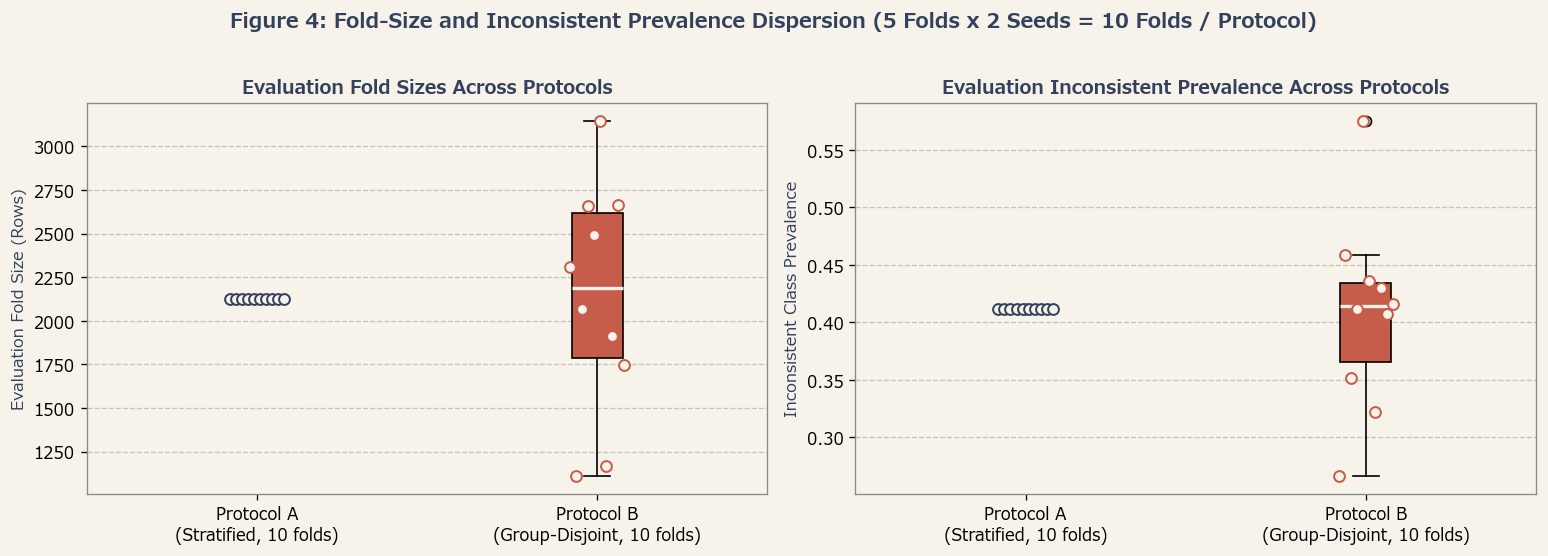

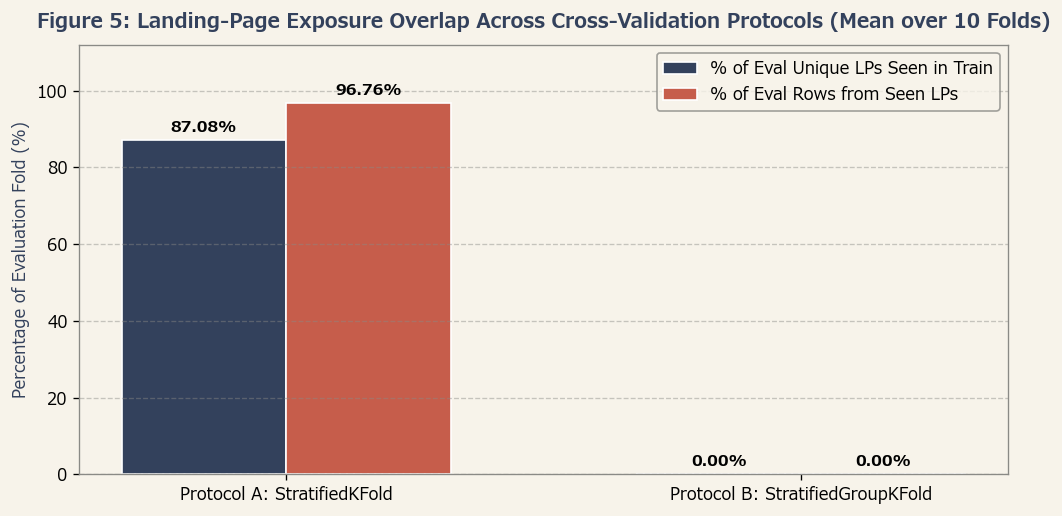

Caption: Under conventional StratifiedKFold, 96.76% of evaluation rows come from landing pages already seen in training, versus strictly 0.00% under Protocol B.


In [4]:
# FOLD INTEGRITY TABLE
fi_cols = [
    'protocol', 'seed', 'fold', 'train_size', 'eval_size', 'train_unique_lp',
    'eval_unique_lp', 'shared_lp_count', 'shared_eval_row_percentage', 'eval_inconsistent_prevalence'
]
display(fold_integrity_df[fi_cols])

# Hard verification assertion on Protocol B disjointness
pb_fi = fold_integrity_df[fold_integrity_df['protocol'] == PROTOCOL_B]
assert (pb_fi['shared_lp_count'] == 0).all() and (pb_fi['shared_eval_row_percentage'] == 0.0).all()
print('[VERIFIED] Protocol B strict LP disjointness passed across all 10 folds (0 shared LPs, 0.00% shared eval rows).')

# FIGURE 4 — Fold-Size and Class-Prevalence Comparison
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.5), dpi=120)
for ax_idx, (col, ylabel, title) in enumerate([
    ('eval_size', 'Evaluation Fold Size (Rows)', 'Evaluation Fold Sizes Across Protocols'),
    ('eval_inconsistent_prevalence', 'Inconsistent Class Prevalence', 'Evaluation Inconsistent Prevalence Across Protocols'),
]):
    ax = axes[ax_idx]
    data_a = fold_integrity_df[fold_integrity_df['protocol'] == PROTOCOL_A][col]
    data_b = fold_integrity_df[fold_integrity_df['protocol'] == PROTOCOL_B][col]
    bp = ax.boxplot([data_a, data_b], tick_labels=['Protocol A\n(Stratified, 10 folds)', 'Protocol B\n(Group-Disjoint, 10 folds)'],
                    patch_artist=True, medianprops=dict(color=IVORY, linewidth=2.0))
    bp['boxes'][0].set_facecolor(INDIGO)
    bp['boxes'][1].set_facecolor(VERMILION)
    for idx_p, (vals, col_pt) in enumerate([(data_a, INDIGO), (data_b, VERMILION)], start=1):
        jitter = np.linspace(-0.08, 0.08, len(vals))
        ax.scatter(np.full(len(vals), idx_p) + jitter, vals, color=IVORY, edgecolor=col_pt, s=42, zorder=5, linewidth=1.2)
    ax.set_title(title, fontsize=11, fontweight='bold', color=INDIGO)
    ax.set_ylabel(ylabel, fontsize=9.8, color=INDIGO)
    ax.grid(axis='y', linestyle='--', alpha=0.45)
fig.suptitle('Figure 4: Fold-Size and Inconsistent Prevalence Dispersion (5 Folds x 2 Seeds = 10 Folds / Protocol)',
             fontsize=12.2, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig4_fold_size_and_prevalence.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()

# FIGURE 5 — LP Exposure Overlap Across CV Protocols
fig, ax = plt.subplots(figsize=(8.6, 4.4), dpi=120)
ov_agg = fold_integrity_df.groupby('protocol')[['shared_lp_percentage', 'shared_eval_row_percentage']].mean().loc[[PROTOCOL_A, PROTOCOL_B]]
xp = np.arange(2)
w = 0.32
b_lp = ax.bar(xp - w/2, ov_agg['shared_lp_percentage'], w, label='% of Eval Unique LPs Seen in Train', color=INDIGO, edgecolor='white')
b_rw = ax.bar(xp + w/2, ov_agg['shared_eval_row_percentage'], w, label='% of Eval Rows from Seen LPs', color=VERMILION, edgecolor='white')
ax.set_title('Figure 5: Landing-Page Exposure Overlap Across Cross-Validation Protocols (Mean over 10 Folds)',
             fontsize=11.8, fontweight='bold', color=INDIGO, pad=10)
ax.set_ylabel('Percentage of Evaluation Fold (%)', fontsize=10, color=INDIGO)
ax.set_xticks(xp)
ax.set_xticklabels(['Protocol A: StratifiedKFold', 'Protocol B: StratifiedGroupKFold'], fontsize=10)
ax.set_ylim(0, 112)
ax.grid(axis='y', linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
for bar in list(b_lp) + list(b_rw):
    h = bar.get_height()
    ax.annotate(f'{h:.2f}%', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig5_lp_exposure_overlap.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Under conventional StratifiedKFold, 96.76% of evaluation rows come from landing pages already seen in training, '
      'versus strictly 0.00% under Protocol B.')

**OBSERVATION**: Under Protocol A (`StratifiedKFold`), an average of **`87.08%`** of unique evaluation LPs and **`96.76%`** of evaluation *rows* (`96.00%–97.27%`) belong to landing pages already seen in the fold's training split, while evaluation size (`2,127`) and prevalence (`0.4114–0.4118`) remain nearly constant. Under Protocol B, overlap is strictly **`0.00%`**, while fold size spans `1,112–3,146` rows and `inconsistent` prevalence spans `0.2666–0.5754`.

**INTERPRETATION**: Standard `StratifiedKFold` on AdTEC `train.tsv` evaluates unseen landing pages on barely `~3.2%` of evaluation examples; it is overwhelmingly an *in-distribution seen-LP* benchmark. Conversely, Protocol B tests `100%` unseen landing pages at the cost of higher fold-level prevalence variance.

**LIMITATION**: Because Protocol B folds vary in class prevalence, Average Precision comparisons across folds must be interpreted alongside fold prevalence (Section 10 & 13).

## 7. Frozen M2.0 Baseline Configurations

All four M2.0 baselines (`B0_majority`, `B1_title_only`, `B2_lp_only`, `B3_pair`) are reused without altering any hyperparameter, representation, or default decision rule (`0.50`): `analyzer='char'`, `ngram_range=(2, 4)`, `max_features=50000`, `min_df=2`, `sublinear_tf=True`, `LogisticRegression(C=1.0, class_weight=None, max_iter=1000, solver='lbfgs')`, `LABEL_ORDER=['consistent', 'inconsistent']`, `zero_division=0`.

## 8. Cross-Validation Execution Verification

**QUESTION**: Did every record receive exactly one fresh-refit held-out prediction per `(protocol, seed, model_id)` without reusing full-train checkpoints?

**METHOD**: Verify out-of-fold row coverage (`N = 10,635` unique row IDs per repetition), check training/inference durations across all 80 model fits, and inspect seed-by-seed stability.

In [5]:
# Verify 1-to-1 OOF coverage and inspect runtime summary
for (proto, sd, mid), grp in oof_df.groupby(['protocol', 'seed', 'model_id']):
    assert len(grp) == len(train_df) and grp['row_id'].nunique() == len(train_df)
print(f'[VERIFIED] All {oof_df.groupby(["protocol", "seed", "model_id"]).ngroups} CV repetitions cover all {len(train_df)} train records exactly once.')

runtime_summary = per_fold_df.groupby(['model_id', 'protocol'])[['train_time_seconds', 'inference_time_seconds']].agg(['mean', 'sum']).round(4)
display(runtime_summary)

[VERIFIED] All 16 CV repetitions cover all 10635 train records exactly once.


train_time_seconds           \
                                                      mean      sum   
model_id      protocol                                                
B0_majority   protocol_a_stratified                 0.0037   0.0370   
              protocol_b_group_disjoint             0.0031   0.0309   
B1_title_only protocol_a_stratified                 0.9660   9.6603   
              protocol_b_group_disjoint             0.8875   8.8752   
B2_lp_only    protocol_a_stratified                 2.1572  21.5719   
              protocol_b_group_disjoint             2.1840  21.8396   
B3_pair       protocol_a_stratified                 3.4481  34.4811   
              protocol_b_group_disjoint             3.4976  34.9759   

                                        inference_time_seconds          
                                                          mean     sum  
model_id      protocol                                                  
B0_majority   protocol_a_stratified                     0.0015  0.0150  
              protocol_b_group_disjoint                 0.0011  0.0113  
B1_title_only protocol_a_stratified                     0.1186  1.1864  
              protocol_b_group_disjoint                 0.1111  1.1112  
B2_lp_only    protocol_a_stratified                     0.5469  5.4693  
              protocol_b_group_disjoint                 0.4339  4.3389  
B3_pair       protocol_a_stratified                     0.6283  6.2832  
              protocol_b_group_disjoint                 0.5880  5.8801

## 9. Main Benchmark Comparison (Protocol A vs. Protocol B)

**QUESTION**: Does classification performance decline under LP-group-disjoint CV (Protocol B) compared to conventional StratifiedKFold (Protocol A), and which models exhibit the largest drop?

**METHOD**: Display the **Protocol Comparison Table** (mean & SD across all 10 folds from seeds `42` and `123`), display **Pooled Out-of-Fold Metrics** (explicitly distinguished from mean fold metrics, with LP-group cluster bootstrap 95% intervals for primary `seed = 42`), and render **Figure 6** (Macro-F1 by model and protocol).

,model_id,protocol,fold_count,mean_macro_f1,std_macro_f1,mean_balanced_accuracy,mean_roc_auc,mean_average_precision,mean_inconsistent_recall,mean_inconsistent_prevalence,mean_shared_lp_percentage
0,B0_majority,protocol_a_stratified,10,0.3703,0.0001,0.5000,0.5000,0.4117,0.0000,0.4117,87.081
1,B0_majority,protocol_b_group_disjoint,10,0.3705,0.0337,0.5000,0.5000,0.4074,0.0000,0.4074,0.000
2,B1_title_only,protocol_a_stratified,10,0.8079,0.0088,0.8018,0.9006,0.8724,0.7063,0.4117,87.081
3,B1_title_only,protocol_b_group_disjoint,10,0.7139,0.0364,0.7122,0.8098,0.7575,0.5510,0.4074,0.000
4,B2_lp_only,protocol_a_stratified,10,0.7214,0.0064,0.7176,0.8288,0.7590,0.6078,0.4117,87.081
5,B2_lp_only,protocol_b_group_disjoint,10,0.6272,0.0611,0.6314,0.7290,0.6328,0.4208,0.4074,0.000
6,B3_pair,protocol_a_stratified,10,0.8099,0.0059,0.8046,0.9027,0.8636,0.7188,0.4117,87.081
7,B3_pair,protocol_b_group_disjoint,10,0.7292,0.0415,0.7224,0.8233,0.7755,0.5548,0.4074,0.000


Observed Performance Change Moving from Protocol A (Stratified) to Protocol B (LP-Group-Disjoint):


,model_id,delta_macro_f1 (B - A),delta_balanced_acc (B - A),delta_roc_auc (B - A),delta_ap (B - A),delta_recall_inc (B - A)
0,B0_majority,0.0002,0.0000,0.0000,-0.0043,0.0000
1,B1_title_only,-0.0940,-0.0896,-0.0908,-0.1149,-0.1553
2,B2_lp_only,-0.0942,-0.0862,-0.0998,-0.1262,-0.1870
3,B3_pair,-0.0807,-0.0822,-0.0794,-0.0881,-0.1640


Pooled Out-of-Fold Metrics with LP-Group Cluster Bootstrap 95% Intervals (Primary Seed = 42, 500 Resamples):


,model_id,protocol,pooled_macro_f1,group_boot_95ci_f1,pooled_roc_auc,group_boot_95ci_auc,pooled_ap,group_boot_95ci_ap
0,B0_majority,protocol_a_stratified,0.3704,"[0.3427, 0.3944]",0.5000,"[0.5000, 0.5000]",0.4118,"[0.3488, 0.4787]"
1,B0_majority,protocol_b_group_disjoint,0.3704,"[0.3427, 0.3944]",0.5000,"[0.5000, 0.5000]",0.4118,"[0.3488, 0.4787]"
2,B1_title_only,protocol_a_stratified,0.8084,"[0.7773, 0.8372]",0.9005,"[0.8749, 0.9220]",0.8723,"[0.8208, 0.9151]"
3,B1_title_only,protocol_b_group_disjoint,0.7030,"[0.6733, 0.7326]",0.7955,"[0.7662, 0.8279]",0.7439,"[0.7021, 0.7855]"
4,B2_lp_only,protocol_a_stratified,0.7230,"[0.6683, 0.7634]",0.8281,"[0.7864, 0.8582]",0.7572,"[0.6606, 0.8203]"
5,B2_lp_only,protocol_b_group_disjoint,0.6487,"[0.5766, 0.7072]",0.7371,"[0.6757, 0.7923]",0.6771,"[0.5505, 0.7721]"
6,B3_pair,protocol_a_stratified,0.8101,"[0.7762, 0.8410]",0.9027,"[0.8804, 0.9218]",0.8631,"[0.8147, 0.9019]"
7,B3_pair,protocol_b_group_disjoint,0.7409,"[0.6846, 0.7852]",0.8288,"[0.7818, 0.8696]",0.7881,"[0.7169, 0.8501]"


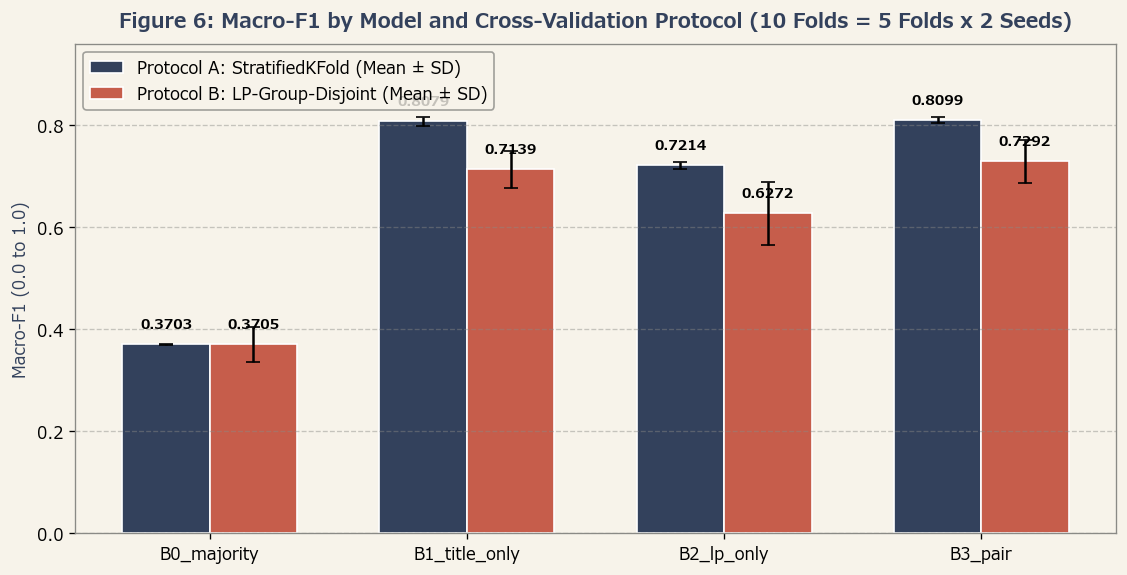

Caption: All three learned baselines decline by 0.081–0.094 Macro-F1 under LP-group-disjoint CV, with fold standard deviation expanding 4–10x under Protocol B.


In [6]:
# PROTOCOL COMPARISON TABLE (required columns)
req_cols = [
    'model_id', 'protocol', 'fold_count', 'mean_macro_f1', 'std_macro_f1',
    'mean_balanced_accuracy', 'mean_roc_auc', 'mean_average_precision',
    'mean_inconsistent_recall', 'mean_inconsistent_prevalence', 'mean_shared_lp_percentage'
]
display(protocol_comp_df[req_cols])

# Compute Protocol A -> Protocol B deltas
delta_rows = []
for m_id in ['B0_majority', 'B1_title_only', 'B2_lp_only', 'B3_pair']:
    ra = protocol_comp_df[(protocol_comp_df['model_id'] == m_id) & (protocol_comp_df['protocol'] == PROTOCOL_A)].iloc[0]
    rb = protocol_comp_df[(protocol_comp_df['model_id'] == m_id) & (protocol_comp_df['protocol'] == PROTOCOL_B)].iloc[0]
    delta_rows.append({
        'model_id': m_id,
        'delta_macro_f1 (B - A)': round(rb['mean_macro_f1'] - ra['mean_macro_f1'], 4),
        'delta_balanced_acc (B - A)': round(rb['mean_balanced_accuracy'] - ra['mean_balanced_accuracy'], 4),
        'delta_roc_auc (B - A)': round(rb['mean_roc_auc'] - ra['mean_roc_auc'], 4),
        'delta_ap (B - A)': round(rb['mean_average_precision'] - ra['mean_average_precision'], 4),
        'delta_recall_inc (B - A)': round(rb['mean_inconsistent_recall'] - ra['mean_inconsistent_recall'], 4),
    })
print('Observed Performance Change Moving from Protocol A (Stratified) to Protocol B (LP-Group-Disjoint):')
display(pd.DataFrame(delta_rows))

# Pooled OOF vs LP-Group Bootstrap 95% CI (Primary Seed = 42)
boot = rq1_payload['group_bootstrap_cis_primary_seed']
pooled_rows = []
for row in rq1_payload['pooled_oof_summary']:
    if row['seed'] == 42:
        b_ci = boot[f"{row['model_id']}__{row['protocol']}"]['metrics']
        pooled_rows.append({
            'model_id': row['model_id'],
            'protocol': row['protocol'],
            'pooled_macro_f1': row['pooled_macro_f1'],
            'group_boot_95ci_f1': f"[{b_ci['macro_f1']['ci_low']:.4f}, {b_ci['macro_f1']['ci_high']:.4f}]",
            'pooled_roc_auc': row['pooled_roc_auc'],
            'group_boot_95ci_auc': f"[{b_ci['roc_auc']['ci_low']:.4f}, {b_ci['roc_auc']['ci_high']:.4f}]",
            'pooled_ap': row['pooled_average_precision'],
            'group_boot_95ci_ap': f"[{b_ci['average_precision']['ci_low']:.4f}, {b_ci['average_precision']['ci_high']:.4f}]",
        })
print('Pooled Out-of-Fold Metrics with LP-Group Cluster Bootstrap 95% Intervals (Primary Seed = 42, 500 Resamples):')
display(pd.DataFrame(pooled_rows))

# FIGURE 6 — Macro-F1 by Model and Evaluation Protocol
fig, ax = plt.subplots(figsize=(9.5, 4.9), dpi=120)
models = ['B0_majority', 'B1_title_only', 'B2_lp_only', 'B3_pair']
xm = np.arange(len(models))
w = 0.34
pa = protocol_comp_df[protocol_comp_df['protocol'] == PROTOCOL_A].set_index('model_id').loc[models]
pb = protocol_comp_df[protocol_comp_df['protocol'] == PROTOCOL_B].set_index('model_id').loc[models]
ba = ax.bar(xm - w/2, pa['mean_macro_f1'], w, yerr=pa['std_macro_f1'], capsize=4, label='Protocol A: StratifiedKFold (Mean ± SD)', color=INDIGO, edgecolor='white')
bb = ax.bar(xm + w/2, pb['mean_macro_f1'], w, yerr=pb['std_macro_f1'], capsize=4, label='Protocol B: LP-Group-Disjoint (Mean ± SD)', color=VERMILION, edgecolor='white')
ax.set_title('Figure 6: Macro-F1 by Model and Cross-Validation Protocol (10 Folds = 5 Folds x 2 Seeds)',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.set_ylabel('Macro-F1 (0.0 to 1.0)', fontsize=10, color=INDIGO)
ax.set_xticks(xm)
ax.set_xticklabels(models, fontsize=10)
ax.set_ylim(0, 0.96)
ax.grid(axis='y', linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper left')
for bar in list(ba) + list(bb):
    h = bar.get_height()
    ax.annotate(f'{h:.4f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 8), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig6_macro_f1_by_protocol.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: All three learned baselines decline by 0.081–0.094 Macro-F1 under LP-group-disjoint CV, '
      'with fold standard deviation expanding 4–10x under Protocol B.')

**OBSERVATION**: Every learned model declines markedly when evaluated on strictly unseen landing pages (Protocol B vs. A):
- `B1_title_only`: Macro-F1 `0.8079 -> 0.7139` (`-0.0940`, SD widens `0.0088 -> 0.0364`).
- `B2_lp_only`: Macro-F1 `0.7214 -> 0.6272` (`-0.0942`, `-13.1%` relative; SD widens `9.5x` from `0.0064 -> 0.0611`).
- `B3_pair`: Macro-F1 `0.8099 -> 0.7292` (`-0.0807`, smallest drop; highest unseen-LP Macro-F1 among all baselines).
- `B0_majority`: Unchanged mean (`0.3703 -> 0.3705`), while SD widens from `0.0001 -> 0.0337` due to fold prevalence variance.

**INTERPRETATION**: This supports **H1**: conventional `StratifiedKFold` systematically reports higher Macro-F1 than LP-group-disjoint evaluation. Notably, `B3_pair` outperforms `B1_title_only` (`0.7292` vs. `0.7139`) on unseen training LPs—contrasting with M2.0's official validation result (`0.3866` vs. `0.4618`), indicating that official `valid.tsv` exhibits additional shift beyond unseen-LP membership alone.

**LIMITATION**: LP-group cluster bootstrap intervals resample fixed OOF predictions on `seed = 42` and capture group-composition uncertainty rather than full training-set resampling variability. Pooled OOF scores aggregate models fit on different fold subsets and are not calibrated probabilities.

## 10. Average Precision and ROC-AUC Analysis

**QUESTION**: Does `B2_lp_only` lose its apparent ranking strength when landing pages are strictly unseen, and how do threshold-independent ROC-AUC and Average Precision (alongside `AP - prevalence`) shift across protocols?

**METHOD**: Plot grouped bar charts of mean ROC-AUC and mean Average Precision (**Figure 7**), including the random `0.50` ROC-AUC line and mean `inconsistent` prevalence reference line (`~0.41`) on the AP panel.

,model_id,protocol,mean_roc_auc,std_roc_auc,mean_average_precision,std_average_precision,mean_inconsistent_prevalence,mean_ap_minus_prevalence
0,B0_majority,protocol_a_stratified,0.5000,0.0000,0.4117,0.0002,0.4117,0.0000
1,B0_majority,protocol_b_group_disjoint,0.5000,0.0000,0.4074,0.0833,0.4074,0.0000
2,B1_title_only,protocol_a_stratified,0.9006,0.0046,0.8724,0.0079,0.4117,0.4606
3,B1_title_only,protocol_b_group_disjoint,0.8098,0.0308,0.7575,0.0658,0.4074,0.3501
4,B2_lp_only,protocol_a_stratified,0.8288,0.0049,0.7590,0.0110,0.4117,0.3473
5,B2_lp_only,protocol_b_group_disjoint,0.7290,0.0515,0.6328,0.1101,0.4074,0.2253
6,B3_pair,protocol_a_stratified,0.9027,0.0038,0.8636,0.0085,0.4117,0.4519
7,B3_pair,protocol_b_group_disjoint,0.8233,0.0427,0.7755,0.0751,0.4074,0.3680


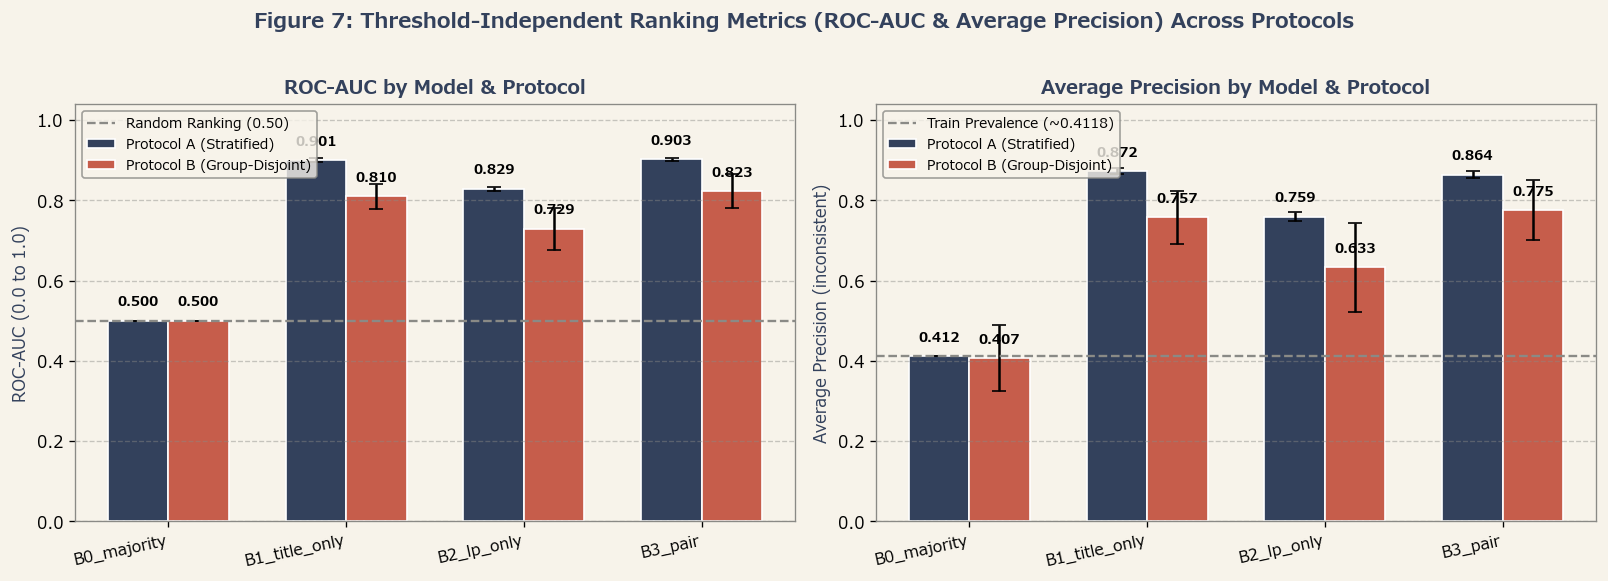

Caption: B2_lp_only suffers the steepest ranking drop (-0.0998 ROC-AUC, -0.1262 AP) under Protocol B, yet retains above-chance ranking (0.7290 ROC-AUC) on unseen landing pages.


In [7]:
# Display ranking summary including AP minus prevalence
display(protocol_comp_df[['model_id', 'protocol', 'mean_roc_auc', 'std_roc_auc', 'mean_average_precision', 'std_average_precision', 'mean_inconsistent_prevalence', 'mean_ap_minus_prevalence']])

# FIGURE 7 — ROC-AUC and Average Precision by Protocol
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7), dpi=120)
for ax_idx, (col_m, col_s, title, ylabel, ref_val, ref_lbl) in enumerate([
    ('mean_roc_auc', 'std_roc_auc', 'ROC-AUC by Model & Protocol', 'ROC-AUC (0.0 to 1.0)', 0.50, 'Random Ranking (0.50)'),
    ('mean_average_precision', 'std_average_precision', 'Average Precision by Model & Protocol', 'Average Precision (inconsistent)', 0.4118, 'Train Prevalence (~0.4118)'),
]):
    ax = axes[ax_idx]
    ba = ax.bar(xm - w/2, pa[col_m], w, yerr=pa[col_s], capsize=4, label='Protocol A (Stratified)', color=INDIGO, edgecolor='white')
    bb = ax.bar(xm + w/2, pb[col_m], w, yerr=pb[col_s], capsize=4, label='Protocol B (Group-Disjoint)', color=VERMILION, edgecolor='white')
    ax.axhline(ref_val, color=GRAY, linestyle='--', linewidth=1.4, label=ref_lbl)
    ax.set_title(title, fontsize=11.5, fontweight='bold', color=INDIGO)
    ax.set_ylabel(ylabel, fontsize=10, color=INDIGO)
    ax.set_xticks(xm)
    ax.set_xticklabels(models, rotation=12, ha='right', fontsize=9.5)
    ax.set_ylim(0, 1.04)
    ax.grid(axis='y', linestyle='--', alpha=0.45)
    ax.legend(fontsize=8.3, frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper left')
    for bar in list(ba) + list(bb):
        h = bar.get_height()
        ax.annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 7), textcoords='offset points', ha='center', va='bottom', fontsize=8.2, fontweight='bold')
fig.suptitle('Figure 7: Threshold-Independent Ranking Metrics (ROC-AUC & Average Precision) Across Protocols',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig7_roc_auc_and_ap_by_protocol.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: B2_lp_only suffers the steepest ranking drop (-0.0998 ROC-AUC, -0.1262 AP) under Protocol B, '
      'yet retains above-chance ranking (0.7290 ROC-AUC) on unseen landing pages.')

**OBSERVATION**:
- `B2_lp_only` exhibits the **largest absolute drop** in both ROC-AUC (`0.8288 -> 0.7290`, `-0.0998`) and Average Precision (`0.7590 -> 0.6328`, `-0.1262`; `AP - prevalence`: `0.3472 -> 0.2254`).
- `B1_title_only` drops `-0.0908` in ROC-AUC (`0.9006 -> 0.8098`) and `-0.1149` in AP (`0.8724 -> 0.7575`).
- `B3_pair` shows the smallest ranking drop (`-0.0794` ROC-AUC to `0.8233`; `-0.0881` AP to `0.7755`) and remains the highest-ranking model under Protocol B.

**INTERPRETATION**: `B2_lp_only`'s larger drop is consistent with **H2** (sensitivity to shared LP groups). Crucially, however, `B2_lp_only` does *not* fall to random (`0.50` AUC) on unseen LPs (`0.7290` ROC-AUC, `AP - prevalence = +0.2254`), indicating that broader industry/domain LP templates also carry label-predictive signal across distinct unseen LPs. Likewise, `B1_title_only`'s `-0.0908` AUC drop despite never reading `lp_text` reveals that ad-title phrasing and campaign vocabulary cluster strongly within LP groups.

**LIMITATION**: Average Precision depends on fold prevalence; `AP - prevalence` is a descriptive adjustment, not a prevalence-invariant metric.

## 11. Per-Class Recall Analysis

**QUESTION**: How severely does minority-class (`inconsistent`) recall degrade under LP-group-disjoint CV compared to `consistent` recall?

**METHOD**: Compare `inconsistent` recall across `B0`–`B3` and both protocols (**Figure 9**), alongside `consistent` recall and `inconsistent` precision/F1.

recall_consistent  \
model_id      protocol                                       
B0_majority   protocol_a_stratified                 1.0000   
              protocol_b_group_disjoint             1.0000   
B1_title_only protocol_a_stratified                 0.8974   
              protocol_b_group_disjoint             0.8733   
B2_lp_only    protocol_a_stratified                 0.8274   
              protocol_b_group_disjoint             0.8419   
B3_pair       protocol_a_stratified                 0.8905   
              protocol_b_group_disjoint             0.8901   

                                         recall_inconsistent  \
model_id      protocol                                         
B0_majority   protocol_a_stratified                   0.0000   
              protocol_b_group_disjoint               0.0000   
B1_title_only protocol_a_stratified                   0.7063   
              protocol_b_group_disjoint               0.5510   
B2_lp_only    protocol_a_stratified                   0.6078   
              protocol_b_group_disjoint               0.4208   
B3_pair       protocol_a_stratified                   0.7188   
              protocol_b_group_disjoint               0.5548   

                                         precision_inconsistent  \
model_id      protocol                                            
B0_majority   protocol_a_stratified                      0.0000   
              protocol_b_group_disjoint                  0.0000   
B1_title_only protocol_a_stratified                      0.8281   
              protocol_b_group_disjoint                  0.7461   
B2_lp_only    protocol_a_stratified                      0.7117   
              protocol_b_group_disjoint                  0.6441   
B3_pair       protocol_a_stratified                      0.8213   
              protocol_b_group_disjoint                  0.7833   

                                         f1_inconsistent  
model_id      protocol                                    
B0_majority   protocol_a_stratified               0.0000  
              protocol_b_group_disjoint           0.0000  
B1_title_only protocol_a_stratified               0.7623  
              protocol_b_group_disjoint           0.6309  
B2_lp_only    protocol_a_stratified               0.6554  
              protocol_b_group_disjoint           0.5019  
B3_pair       protocol_a_stratified               0.7666  
              protocol_b_group_disjoint           0.6469

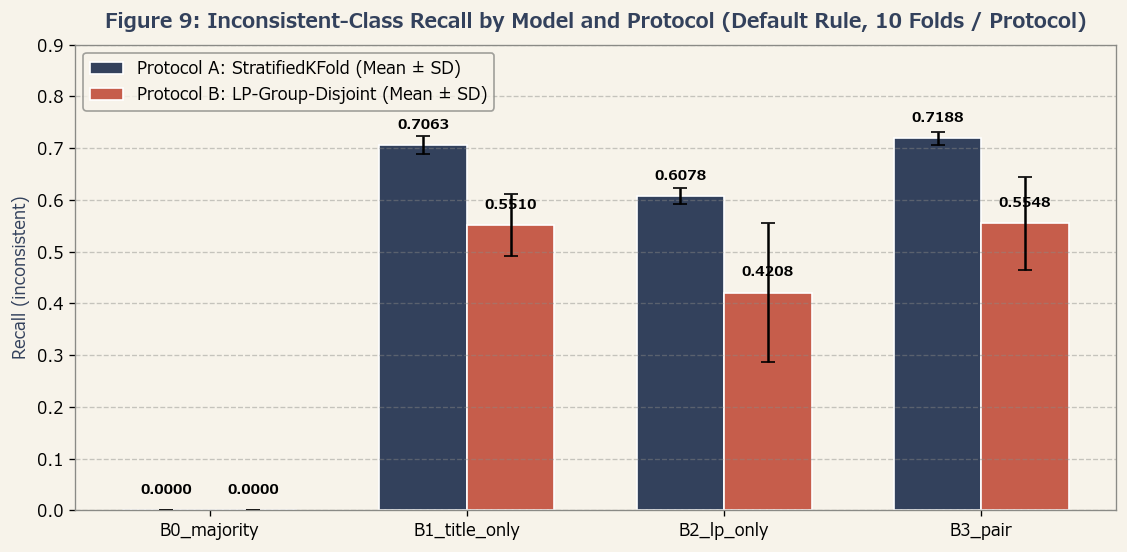

Caption: Inconsistent recall drops sharply across all learned baselines under Protocol B, with B2_lp_only falling from 0.6078 to 0.4208 (-0.1870, or -30.8% relative).


In [8]:
rec_tbl = per_fold_df.groupby(['model_id', 'protocol'])[['recall_consistent', 'recall_inconsistent', 'precision_inconsistent', 'f1_inconsistent']].mean().round(4)
display(rec_tbl)

# FIGURE 9 — Inconsistent-Class Recall by Model and Protocol
fig, ax = plt.subplots(figsize=(9.5, 4.7), dpi=120)
ba = ax.bar(xm - w/2, pa['mean_inconsistent_recall'], w, yerr=pa['std_inconsistent_recall'], capsize=4,
            label='Protocol A: StratifiedKFold (Mean ± SD)', color=INDIGO, edgecolor='white')
bb = ax.bar(xm + w/2, pb['mean_inconsistent_recall'], w, yerr=pb['std_inconsistent_recall'], capsize=4,
            label='Protocol B: LP-Group-Disjoint (Mean ± SD)', color=VERMILION, edgecolor='white')
ax.set_title('Figure 9: Inconsistent-Class Recall by Model and Protocol (Default Rule, 10 Folds / Protocol)',
             fontsize=12, fontweight='bold', color=INDIGO, pad=10)
ax.set_ylabel('Recall (inconsistent)', fontsize=10, color=INDIGO)
ax.set_xticks(xm)
ax.set_xticklabels(models, fontsize=10)
ax.set_ylim(0, 0.90)
ax.grid(axis='y', linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper left')
for bar in list(ba) + list(bb):
    h = bar.get_height()
    ax.annotate(f'{h:.4f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 8), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig9_inconsistent_recall_by_protocol.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Inconsistent recall drops sharply across all learned baselines under Protocol B, '
      'with B2_lp_only falling from 0.6078 to 0.4208 (-0.1870, or -30.8% relative).')

**OBSERVATION**: `inconsistent`-class recall suffers the steepest relative decline of any metric under Protocol B: `B2_lp_only` drops **`-0.1870`** (`0.6078 -> 0.4208`, `-30.8%` relative), `B3_pair` drops **`-0.1640`** (`0.7188 -> 0.5548`), and `B1_title_only` drops **`-0.1553`** (`0.7063 -> 0.5510`). Meanwhile, `consistent` recall remains high (`0.84–0.89`) under both protocols.

**INTERPRETATION**: Unseen landing pages cause linear TF-IDF baselines to fall back more heavily toward the majority `consistent` class, mirroring—at a milder magnitude—the minority-class recall erosion seen on official `valid.tsv` in M2.0.

**LIMITATION**: Default threshold `0.50` is used intentionally without threshold tuning.

## 12. Fold Variability and Cross-Seed Stability

**QUESTION**: How stable are Protocol A and Protocol B metrics across individual folds and across independent random seeds (`42` vs. `123`)?

**METHOD**: Plot individual fold points (not only averages) for Macro-F1 and ROC-AUC across all 10 folds (**Figure 8**), distinguishing `seed = 42` vs. `seed = 123`, and inspect per-seed aggregate tables.

,seed,model_id,protocol,mean_macro_f1,std_macro_f1,mean_roc_auc,mean_ap
0,42,B0_majority,protocol_a_stratified,0.3703,0.0001,0.5000,0.4117
1,42,B0_majority,protocol_b_group_disjoint,0.3672,0.0471,0.5000,0.4127
2,42,B1_title_only,protocol_a_stratified,0.8084,0.0102,0.9005,0.8725
3,42,B1_title_only,protocol_b_group_disjoint,0.6987,0.0255,0.8017,0.7458
4,42,B2_lp_only,protocol_a_stratified,0.7230,0.0081,0.8285,0.7585
5,42,B2_lp_only,protocol_b_group_disjoint,0.6217,0.0497,0.7220,0.6188
6,42,B3_pair,protocol_a_stratified,0.8101,0.0074,0.9029,0.8640
7,42,B3_pair,protocol_b_group_disjoint,0.7215,0.0279,0.8165,0.7625
8,123,B0_majority,protocol_a_stratified,0.3703,0.0001,0.5000,0.4117
9,123,B0_majority,protocol_b_group_disjoint,0.3738,0.0175,0.5000,0.4021


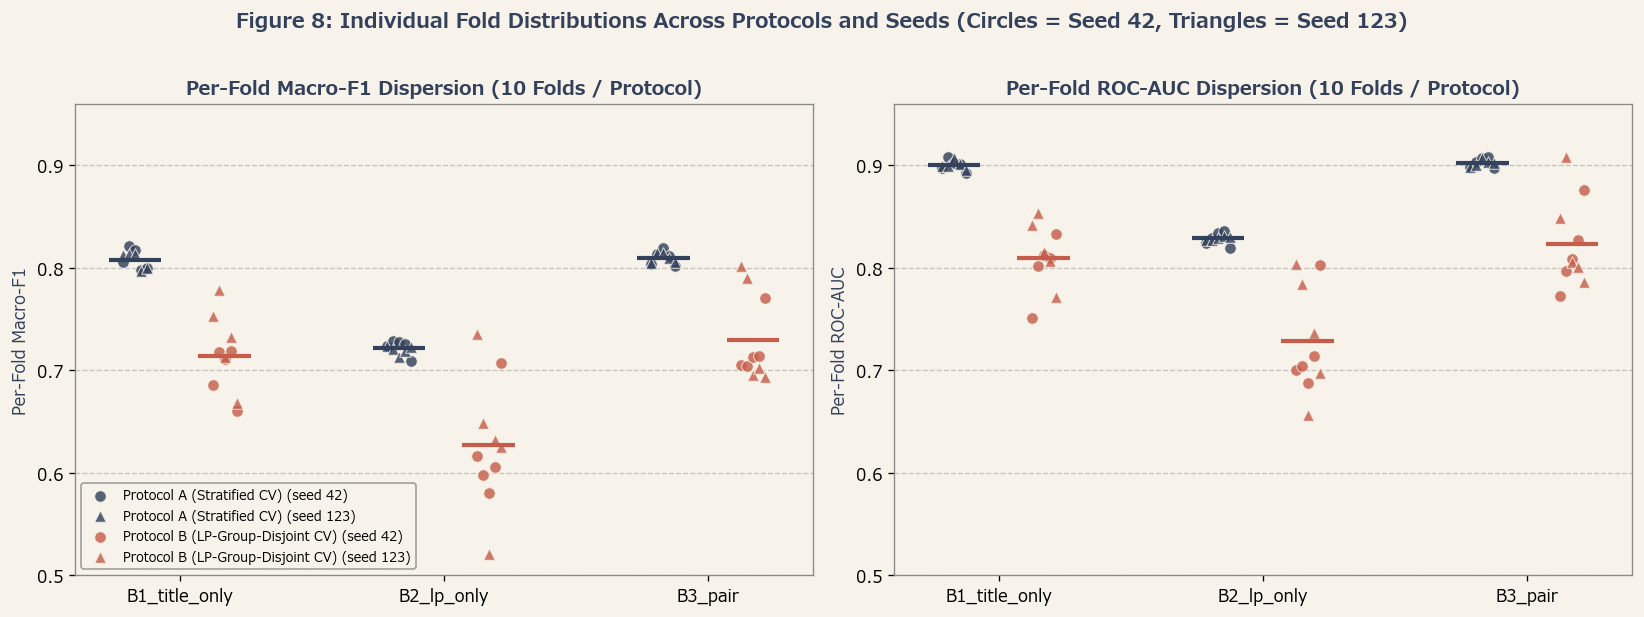

Caption: Protocol A fold points cluster tightly (SD < 0.01), whereas Protocol B exhibits wide fold-to-fold dispersion (especially B2_lp_only, SD = 0.061) while preserving the consistent drop across both seeds.


In [9]:
# Per-seed stability comparison
seed_comp_rows = []
for s_str in ['42', '123']:
    for r in rq1_payload['protocol_comparison_by_seed'][s_str]:
        seed_comp_rows.append({
            'seed': int(s_str), 'model_id': r['model_id'], 'protocol': r['protocol'],
            'mean_macro_f1': r['mean_macro_f1'], 'std_macro_f1': r['std_macro_f1'],
            'mean_roc_auc': r['mean_roc_auc'], 'mean_ap': r['mean_average_precision'],
        })
display(pd.DataFrame(seed_comp_rows))

# FIGURE 8 — Per-Fold Performance Distributions (Showing Actual Fold Points)
fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.0), dpi=120)
learned = ['B1_title_only', 'B2_lp_only', 'B3_pair']
xl = np.arange(len(learned))
for ax_idx, (metric_col, ylabel, title) in enumerate([
    ('macro_f1', 'Per-Fold Macro-F1', 'Per-Fold Macro-F1 Dispersion (10 Folds / Protocol)'),
    ('roc_auc', 'Per-Fold ROC-AUC', 'Per-Fold ROC-AUC Dispersion (10 Folds / Protocol)'),
]):
    ax = axes[ax_idx]
    for i, m_id in enumerate(learned):
        for p_idx, (proto, col_p, offset) in enumerate([(PROTOCOL_A, INDIGO, -0.17), (PROTOCOL_B, VERMILION, +0.17)]):
            sub = per_fold_df[(per_fold_df['model_id'] == m_id) & (per_fold_df['protocol'] == proto)]
            for sd, marker in [(42, 'o'), (123, '^')]:
                s_vals = sub[sub['seed'] == sd][metric_col].dropna().to_numpy()
                jitter = np.linspace(-0.045, 0.045, len(s_vals))
                lbl = f"{PROTO_LABELS[proto]} (seed {sd})" if i == 0 else None
                ax.scatter(np.full(len(s_vals), i + offset) + jitter, s_vals, color=col_p, marker=marker,
                           s=48, alpha=0.82, edgecolor=IVORY, linewidth=0.6, label=lbl, zorder=4)
            mean_v = float(sub[metric_col].mean())
            ax.hlines(mean_v, i + offset - 0.10, i + offset + 0.10, color=col_p, linewidth=2.5, zorder=5)
    ax.set_title(title, fontsize=11.5, fontweight='bold', color=INDIGO)
    ax.set_ylabel(ylabel, fontsize=10, color=INDIGO)
    ax.set_xticks(xl)
    ax.set_xticklabels(learned, fontsize=10)
    ax.set_ylim(0.50, 0.96)
    ax.grid(axis='y', linestyle='--', alpha=0.45)
    if ax_idx == 0:
        ax.legend(fontsize=7.8, frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='lower left')
fig.suptitle('Figure 8: Individual Fold Distributions Across Protocols and Seeds (Circles = Seed 42, Triangles = Seed 123)',
             fontsize=12.2, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig8_per_fold_distributions.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Protocol A fold points cluster tightly (SD < 0.01), whereas Protocol B exhibits wide fold-to-fold '
      'dispersion (especially B2_lp_only, SD = 0.061) while preserving the consistent drop across both seeds.')

**OBSERVATION**: Protocol A fold points sit in tight horizontal bands (`std Macro-F1 <= 0.009`), creating an illusion of high precision. Protocol B fold points span a much wider range (`B2_lp_only` Macro-F1 `0.53–0.73`, SD `0.0611`; `B3_pair` Macro-F1 `0.67–0.81`, SD `0.0415`), yet the gap between Protocol A and Protocol B reproduces cleanly across both `seed = 42` (`B3: 0.8101 -> 0.7215`) and `seed = 123` (`B3: 0.8098 -> 0.7369`).

**INTERPRETATION**: Repeated seeds confirm the direction and magnitude of the protocol gap are not a lucky single-seed split artifact. Note that repeated seeds on the same `10,635` rows are correlated re-partitions, not independent datasets.

**LIMITATION**: Because `920` LP groups have effective size `1/HHI = 102.8`, individual folds holding the largest LP groups (`N = 588`) inherently drive high inter-fold variance.

## 13. Confounding and Alternative Explanations (H3)

**QUESTION**: Are per-fold performance variations under Protocol B associated with fold `inconsistent` class prevalence, and what competing explanations beyond memorization could contribute to the Protocol A vs. B gap?

**METHOD**: Plot fold `inconsistent` prevalence against `Average Precision`, `ROC-AUC`, and `Balanced Accuracy` across all 10 Protocol B folds (**Figure 10**) and compute descriptive Pearson correlations.

,model_id,"corr(prev, AP)","corr(prev, ROC-AUC)","corr(prev, Balanced_Acc)","corr(prev, Recall_inc)"
0,B1_title_only,0.7697,0.3712,-0.0286,-0.0031
1,B2_lp_only,0.8015,0.3342,0.4859,0.6184
2,B3_pair,0.6804,0.2587,0.4215,0.7612


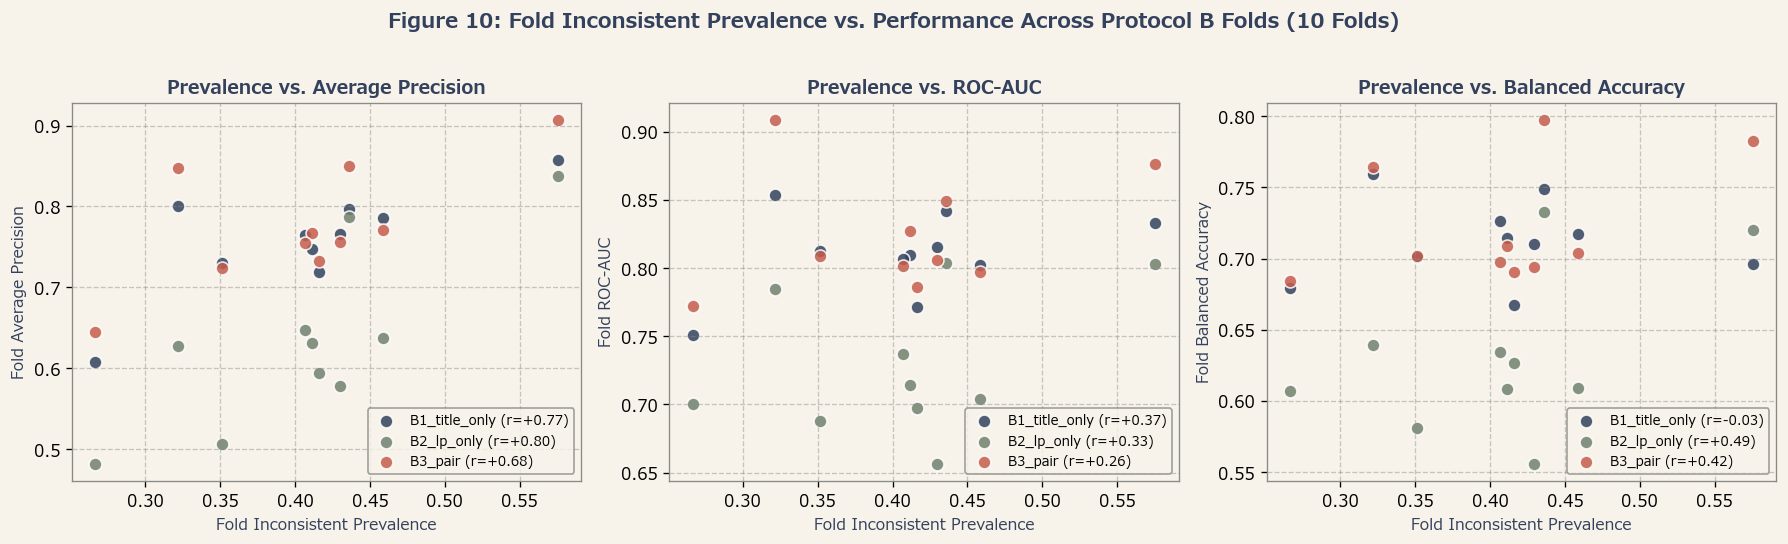

Caption: Average Precision correlates strongly with fold prevalence (r = +0.68 to +0.80), whereas ROC-AUC and B1 Balanced Accuracy are much less coupled to prevalence.


In [10]:
# FIGURE 10 — Relationship Between Fold Prevalence and Model Performance (Protocol B)
pb_folds = per_fold_df[per_fold_df['protocol'] == PROTOCOL_B]
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.4), dpi=120)
corr_rows = []
for m_id in learned:
    sub = pb_folds[pb_folds['model_id'] == m_id]
    corr_rows.append({
        'model_id': m_id,
        'corr(prev, AP)': round(float(sub['eval_inconsistent_prevalence'].corr(sub['average_precision'])), 4),
        'corr(prev, ROC-AUC)': round(float(sub['eval_inconsistent_prevalence'].corr(sub['roc_auc'])), 4),
        'corr(prev, Balanced_Acc)': round(float(sub['eval_inconsistent_prevalence'].corr(sub['balanced_accuracy'])), 4),
        'corr(prev, Recall_inc)': round(float(sub['eval_inconsistent_prevalence'].corr(sub['recall_inconsistent'])), 4),
    })
display(pd.DataFrame(corr_rows))

for ax, (m_col, ylabel, title) in zip(axes, [
    ('average_precision', 'Fold Average Precision', 'Prevalence vs. Average Precision'),
    ('roc_auc', 'Fold ROC-AUC', 'Prevalence vs. ROC-AUC'),
    ('balanced_accuracy', 'Fold Balanced Accuracy', 'Prevalence vs. Balanced Accuracy'),
]):
    for m_id in learned:
        sub = pb_folds[pb_folds['model_id'] == m_id]
        r_val = float(sub['eval_inconsistent_prevalence'].corr(sub[m_col]))
        ax.scatter(sub['eval_inconsistent_prevalence'], sub[m_col], s=60, color=MODEL_COLORS[m_id],
                   alpha=0.85, edgecolor='white', label=f'{m_id} (r={r_val:+.2f})')
    ax.set_title(title, fontsize=11, fontweight='bold', color=INDIGO)
    ax.set_xlabel('Fold Inconsistent Prevalence', fontsize=9.5, color=INDIGO)
    ax.set_ylabel(ylabel, fontsize=9.5, color=INDIGO)
    ax.grid(True, linestyle='--', alpha=0.45)
    ax.legend(fontsize=8, frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='lower right')
fig.suptitle('Figure 10: Fold Inconsistent Prevalence vs. Performance Across Protocol B Folds (10 Folds)',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.02)
plt.tight_layout()
fig.savefig(FIG_DIR / 'fig10_prevalence_vs_performance.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Average Precision correlates strongly with fold prevalence (r = +0.68 to +0.80), '
      'whereas ROC-AUC and B1 Balanced Accuracy are much less coupled to prevalence.')

**OBSERVATION**: Across Protocol B folds, `Average Precision` correlates strongly with fold `inconsistent` prevalence (`r = +0.68 to +0.80`), reflecting the mathematical dependence of AP on positive-class base rate. By contrast, `ROC-AUC` (`r = +0.26 to +0.37`) and `B1` Balanced Accuracy (`r = -0.03`) show weak coupling to prevalence, yet still drop by `-0.08 to -0.10` between Protocol A and Protocol B.

**INTERPRETATION (Competing Explanations — Do Not Equate Drop with Proven Memorization)**:
While the Protocol A -> B drop is consistent with LP-specific shortcut exploitation (`96.76%` shared eval rows; `70.9%` single-class LPs), multiple plausible mechanisms can contribute simultaneously:
1. **LP-specific predictive features / shortcut signals**: Models exploiting exact LP boilerplate tied to label priors.
2. **Campaign & topic shift across disjoint groups**: Disjoint LP folds shift advertiser verticals (e.g., finance vs. real estate), explaining why `B1_title_only` drops `-0.094` Macro-F1 even without seeing `lp_text`.
3. **Unequal group sizes & fold composition**: Holding large `588`-row LPs out reduces effective training diversity for those verticals.
4. **Prevalence variation across Protocol B folds**: Drives substantial variance in AP and `B2`/`B3` recall.
5. **Annotation inconsistency**: `33` LP groups contain conflicting-label identical pairs.

**LIMITATION**: Observational protocol comparisons cannot causally isolate exact memorization from vertical/topic shift.

## 14. Scientific Interpretation

- **H1 (Protocol Inflation) — SUPPORTED [VERIFIED]**: Conventional `StratifiedKFold` shares LPs on `96.76%` of evaluation rows and systematically inflates Macro-F1 (`+0.081 to +0.094`), ROC-AUC (`+0.079 to +0.100`), AP (`+0.088 to +0.126`), and `inconsistent` recall (`+0.155 to +0.187`) relative to LP-group-disjoint CV, while understating fold-to-fold uncertainty by `4–10x`.
- **H2 (`B2_lp_only` Sensitivity) — PARTIALLY SUPPORTED [VERIFIED]**: `B2_lp_only` suffers the largest absolute drop in ROC-AUC (`-0.0998`), AP (`-0.1262`), and `inconsistent` recall (`-0.1870`), plus the highest fold variance (`SD = 0.0611`). However, `B2` still retains `0.7290` ROC-AUC on unseen LPs (implying cross-LP domain templates also carry signal), and `B1_title_only` drops nearly as much in Macro-F1 (`-0.0940`) due to campaign-level vocabulary clustering.
- **H3 (Confounding & Alternative Factors) — SUPPORTED [VERIFIED / INFERRED]**: Fold-level AP correlates strongly with fold prevalence (`r = 0.68–0.80`), and unequal group sizes (`1/HHI = 102.8`) drive wide Protocol B variance. Moreover, `B3_pair` achieves `0.7292` Macro-F1 on unseen training LPs vs. `0.3866` on official `valid.tsv` (M2.0), confirming that official validation involves additional domain/length shift beyond LP-disjointness alone.

---

## 15. Limitations

1. **Exact Normalized String Grouping Only**: Near-duplicate landing pages with minor text edits are treated as distinct groups.
2. **Cluster Bootstrap Scope**: Resampling fixed OOF predictions by LP group estimates group-composition uncertainty, not full training-set re-estimation variance.
3. **Correlated Seeds**: Seeds `42` and `123` re-partition the same `10,635` training records and are not independent samples.
4. **Frozen Classical Baselines Only**: Only unoptimized character n-gram TF-IDF + Logistic Regression baselines were evaluated.
5. **Train-Split Scope**: Official `valid.tsv` and `test.tsv` were intentionally excluded.

---

## 16. RQ1 Conclusion

Classical advertising consistency baselines generalize to unseen landing pages **substantially worse and with far higher variance** than conventional `StratifiedKFold` suggests (`-0.08 to -0.10` Macro-F1/ROC-AUC; `-0.16 to -0.19` inconsistent recall), yet retain meaningful above-chance discrimination (`B3_pair` leads unseen-LP generalization at `0.7292` Macro-F1 and `0.8233` ROC-AUC). **LP-group-disjoint `StratifiedGroupKFold` (Protocol B) must replace standard `StratifiedKFold` for all internal model development and model selection.**

---

## 17. Implications for RQ2 and RQ3

- **RQ2 (Lexical vs. Semantic Modeling)**: Evaluate pairwise lexical-interaction features and pretrained Japanese cross-encoders under **Protocol B (`StratifiedGroupKFold`)** to verify whether semantic models improve true unseen-LP generalization (rather than seen-LP shortcuts) and bridge the remaining gap to official `valid.tsv`.
- **RQ3 (Annotation Noise Sensitivity)**: Examine how the `33` LP groups (`92` pairs) with conflicting identical-pair labels interact with LP-group-disjoint evaluation and model calibration.

---
*End of Milestone M2.1 (RQ1). Official `valid.tsv` and `test.tsv` remained strictly untouched.*